<a href="https://colab.research.google.com/github/a2w3r4/Discovery-Sub-Elementary-Particles/blob/main/Discover_Higgs_Boson_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Standard Model of Fundamental Physics

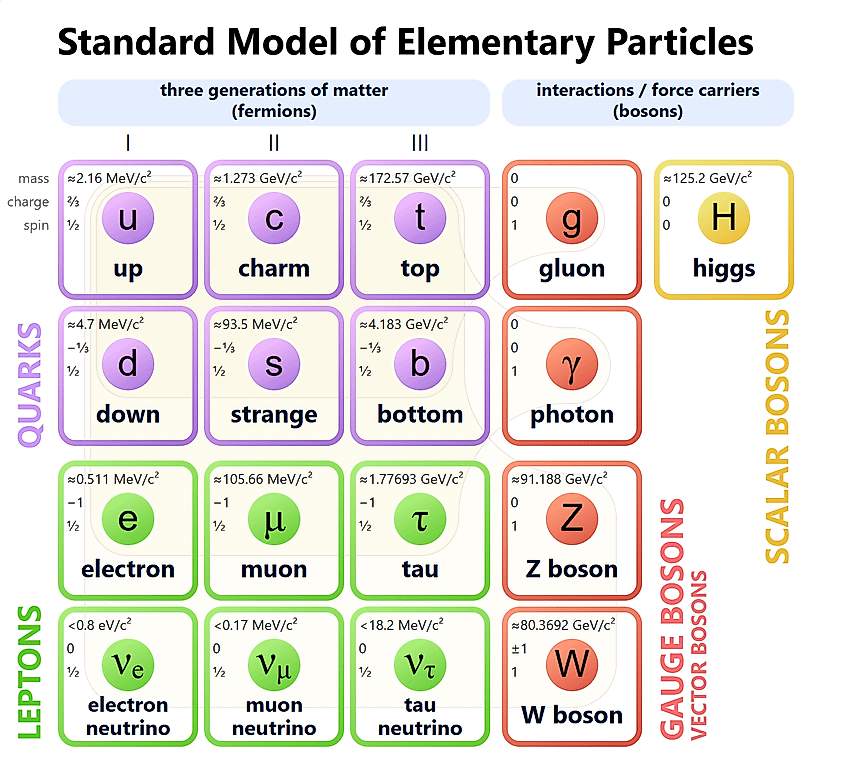

This exercise is aimed towards those interested in experimental high-energy physics with limited programming experience. Readers will be introduced to Python and the needed packages (such as Uproot and NumPy) to complete three activities:

Use real data to plot the masses of di-lepton systems to observe a peak at the mass of the Z boson
Use simulated data to observe a peak at the mass of the Higgs boson
Use real data to observe a peak at the mass of the Higgs boson

In the following activities, you will be working with four different kinds of particles: electrons ( e ), muons ( μ ) (both matter and antimatter variants), Z bosons and Higgs bosons. Electrons and muons are members of a subset of particles called leptons. Both particles are of charge -1 (meaning their anti-particles are both of charge +1) and have a longer lifespan than the Z and Higgs Bosons. The Z boson is a neutral particle (a particle of zero charge) that mediates the weak interaction. The Higgs boson is a neutral particle that couples to other particles to give them mass.

# ***Physics Context***

**# Mass and 4 Vectors**

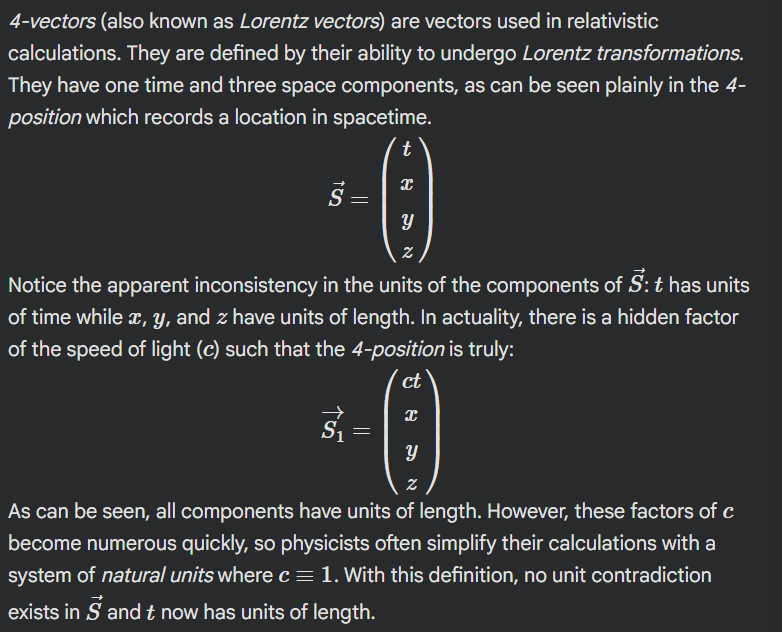

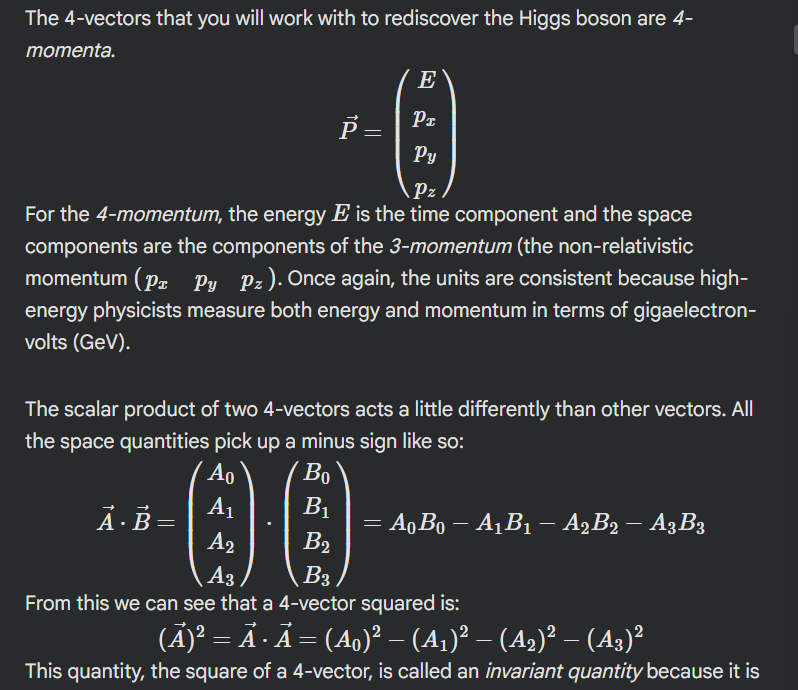

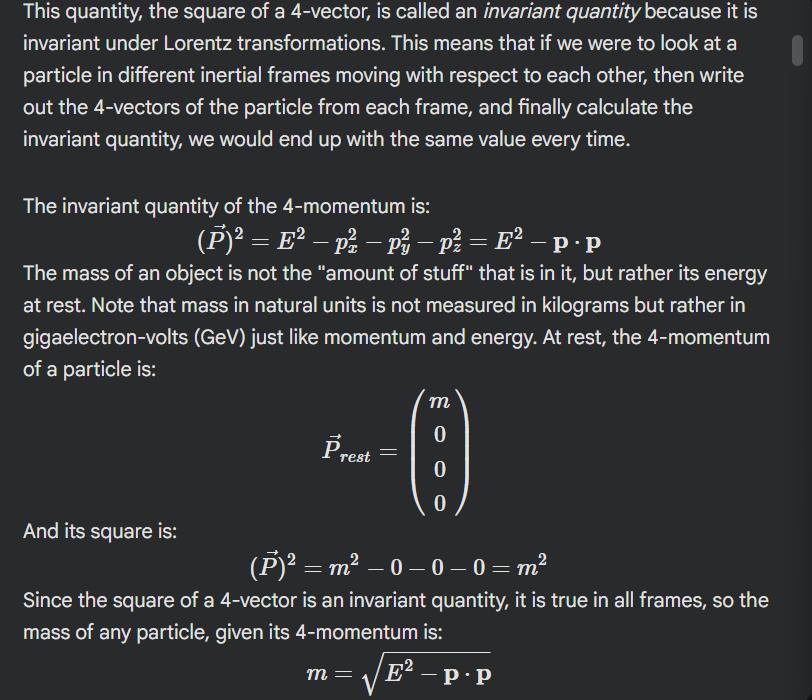

This is the relation that we will use to caluculate the masses of the Z and Higgs bosons

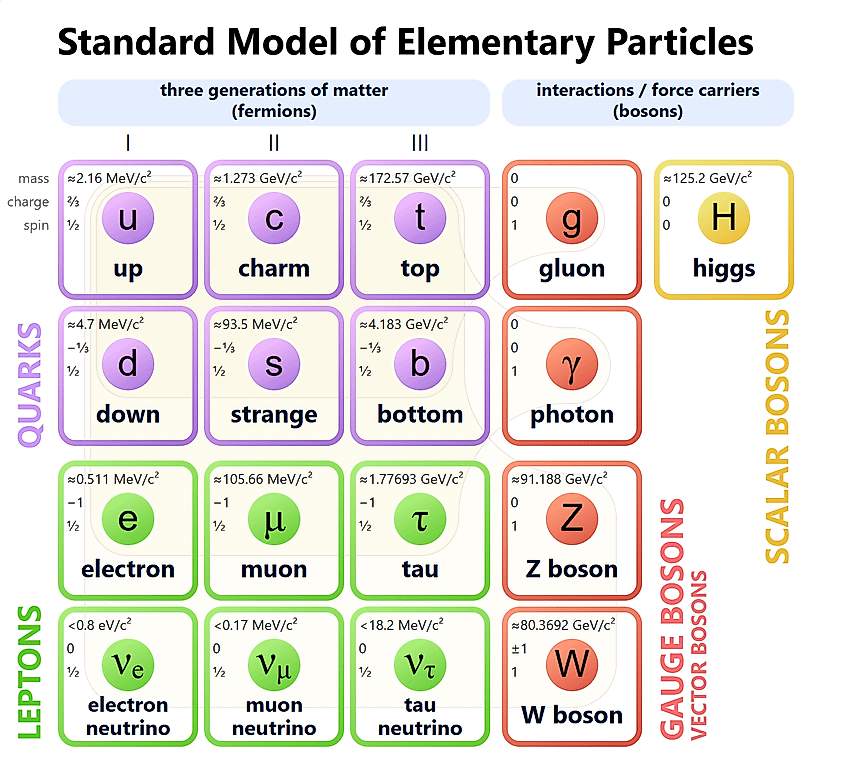

In the following activities, you will be working with four different kinds of particles: electrons ( e ), muons ( μ ) (both matter and antimatter variants), Z bosons and Higgs bosons. Electrons and muons are members of a subset of particles called leptons. Both particles are of charge -1 (meaning their anti-particles are both of charge +1) and have a longer lifespan than the Z and Higgs Bosons. The Z boson is a neutral particle (a particle of zero charge) that mediates the weak interaction. The Higgs boson is a neutral particle that couples to other particles to give them mass.

# Decay Modes

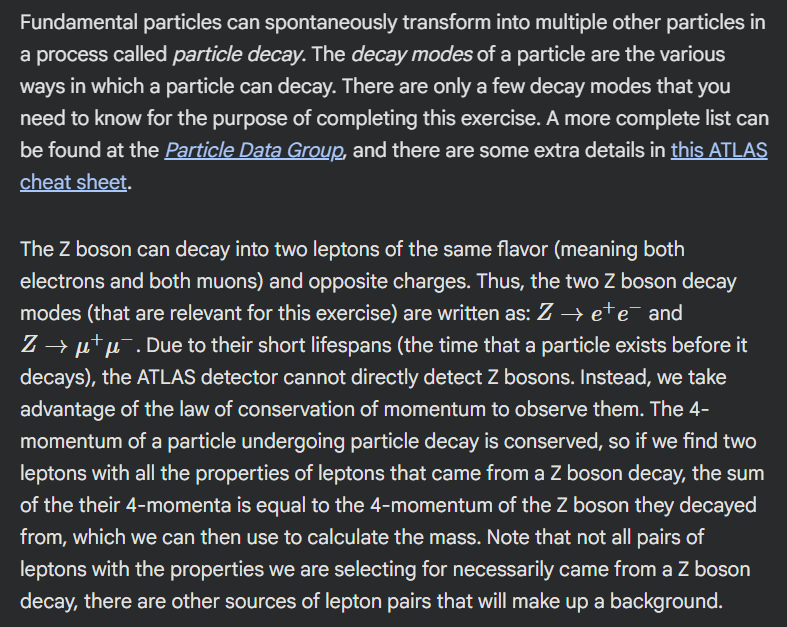

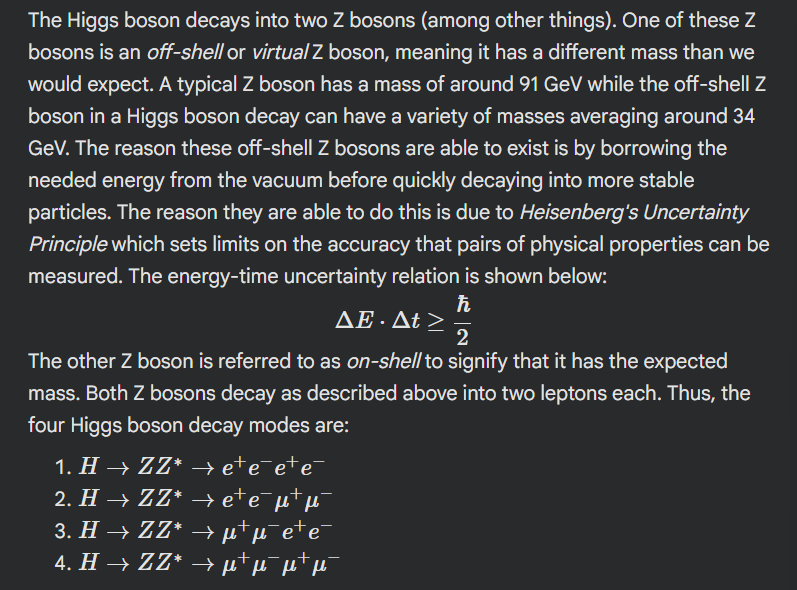

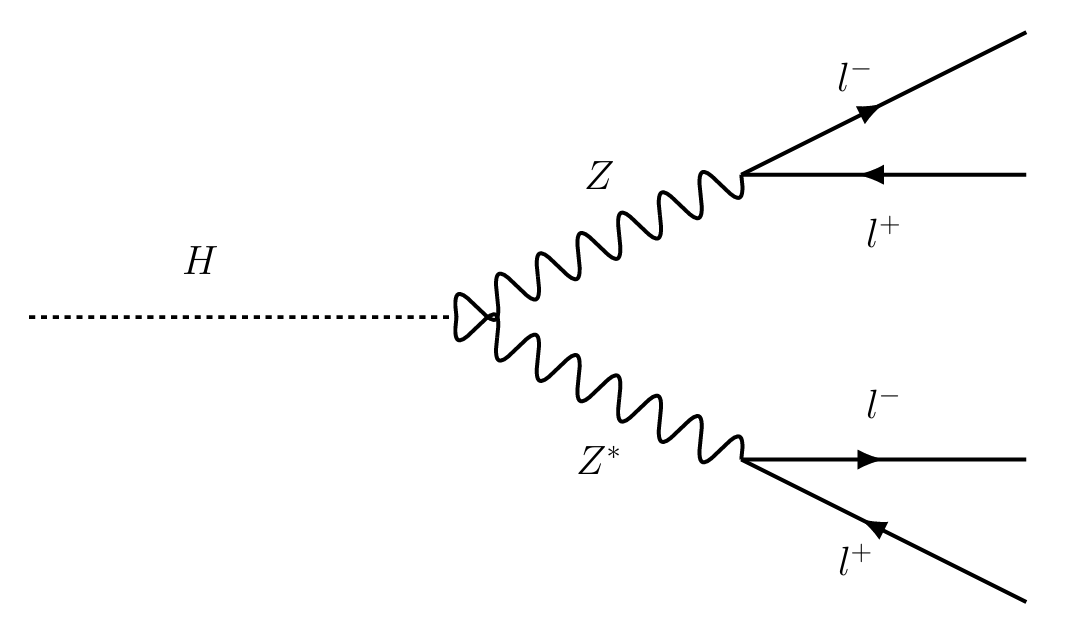

Much like the Z boson, we will not be directly observing the Higgs Boson in ATLAS open data, instead, we will look for 4 leptons that meet all the characteristics of leptons which would have decayed from a Higgs boson, then we will add together their 4-vectors to obtain a 4-vector for the Higgs boson they decayed from.

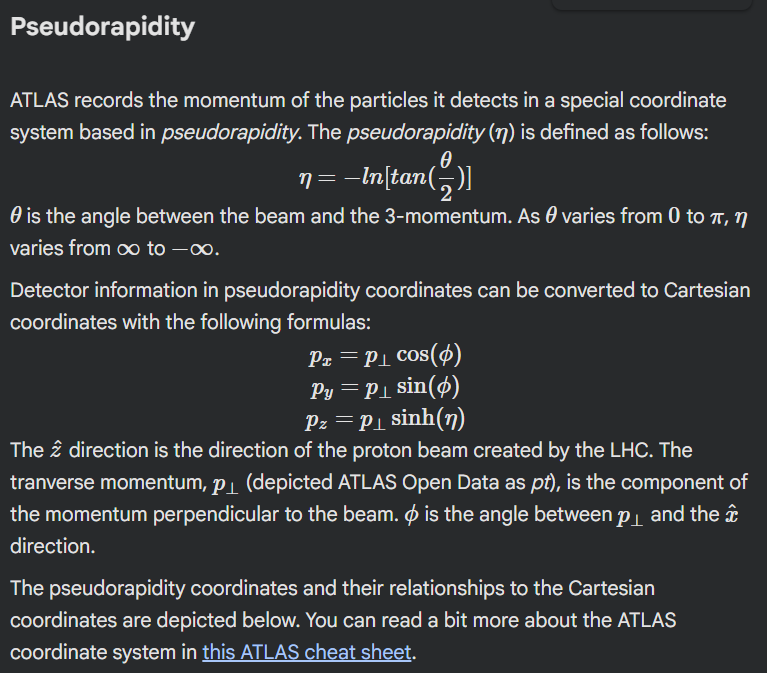

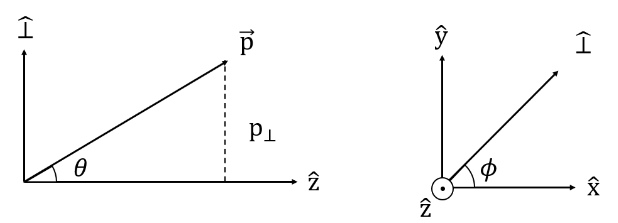

#Particle Analysis

In [ ]:
import numpy as np

In [ ]:
a = np.array([1,4,9,16,25])

In [ ]:
a+5

array([ 6,  9, 14, 21, 30])

In [ ]:
np.sqrt(a)

array([1., 2., 3., 4., 5.])

In [ ]:
a = np.array([[1,2,3],[4,5,6]])
b = np.array([[7,8,9],[10,11,12]])
a+b,   a-b,   a*b,   a/b

(array([[ 8, 10, 12],
        [14, 16, 18]]),
 array([[-6, -6, -6],
        [-6, -6, -6]]),
 array([[ 7, 16, 27],
        [40, 55, 72]]),
 array([[0.14285714, 0.25      , 0.33333333],
        [0.4       , 0.45454545, 0.5       ]]))

In [ ]:
np.concatenate([a,b], axis=0)

array([[ 1,  2,  3],
       [ 4,  5,  6],
       [ 7,  8,  9],
       [10, 11, 12]])

In [ ]:
np.concatenate([a,b],axis=1)

array([[ 1,  2,  3,  7,  8,  9],
       [ 4,  5,  6, 10, 11, 12]])

In [ ]:
# Create an array of random integers
a = np.random.randint(low=0, high=10, size=(5,5))
a

array([[0, 9, 8, 2, 1],
       [1, 2, 5, 9, 4],
       [8, 1, 5, 1, 7],
       [2, 7, 7, 5, 9],
       [0, 4, 9, 0, 1]])

In [ ]:
np.sort(a, axis=0)

array([[0, 1, 5, 0, 1],
       [0, 2, 5, 1, 1],
       [1, 4, 7, 2, 4],
       [2, 7, 8, 5, 7],
       [8, 9, 9, 9, 9]])

In [ ]:
np.sort(a, axis=1)

array([[0, 1, 2, 8, 9],
       [1, 2, 4, 5, 9],
       [1, 1, 5, 7, 8],
       [2, 5, 7, 7, 9],
       [0, 0, 1, 4, 9]])

# Activity 1 : Z Peak

In this activity, we will:

1. Turn ATLAS open data into arrays that can be used in Python.
2. Create selections to remove any events that did not contain a Z boson.
3. Use the properties of 4-vectors to calculate the masses of the Z bosons.
4. Plot the masses of the Z bosons.

In [ ]:
!pip install uproot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 441.2/441.2 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 698.7/698.7 kB 42.1 MB/s eta 0:00:00


In [ ]:
import numpy as np
import uproot   # used for opening .root files
import matplotlib.pyplot as plt  # used for drawing plots
import matplotlib.text # used for adding text to plots

# Using ATLAS Open Data
To open a file, you need to either have a root file stored to your hard drive or a url for a file stored on the internet. You will be importing our data from the ATLAS experiment using the package ATLAS Open Magic. Further information on the package can be found here. First, install the data to your computer (if you have not done so already). This can be done by executing the cell below. Any additional python packages not already installed on your computer can be installed with pip install name-of-needed-package.

In [ ]:
import sys
%pip install atlasopenmagic
from atlasopenmagic import install_from_environment
install_from_environment()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 1.5 MB/s eta 0:00:00
Installing packages: ['aiohttp>=3.9.5', 'atlasopenmagic>=1.9.0', 'awkward>=2.6.7', 'awkward-pandas>=2023.8.0', 'coffea~=0.7.0', 'fsspec>=2025.7.0', 'hist>=2.8.0', 'ipykernel>=6.29.5', 'jupyter>=1.0.0', 'lmfit>=1.3.2', 'matplotlib>=3.9.1', 'metakernel>=0.30.2', 'notebook<7', 'numpy>=1.26.4', 'pandas>=2.2.2', 'papermill>=2.6.0', 'pip>=24.2', 'scikit-learn>=1.5.1', 'uproot>=5.3.10', 'uproot3>=3.14.4', 'fsspec-xrootd>=0.5.1', 'jupyterlab_latex~=3.1.0', 'vector>=1.4.1']


Next, import the atlasopenmagic package as atom and set the available release using atom.set_release(). If you want to see all your options for the release, run atom.available_releases().

In [ ]:
import atlasopenmagic as atom
atom.set_release('2025e-13tev-beta')

Now, we will access a list of files from the release. We first need to set the skim. The skim is essentially a filter for the type of data you want to open. You can check all your options for the skim by running atom.available_skims(). Now, define a list of files with the value returned by the method atom.get_urls().

In [ ]:
# the skin onllyy pulls out events with 2 to 4 leptons
skim = '2to4lep'
# Get the real detctor data
files_list  = atom.get_urls('data', skim, protocol = 'https', cache=True)

In [ ]:
files_list

# Using Uproot
Uproot is a Python package used for reading ROOT files in Python. A more extensive look at its usage can be found at the Uproot documentation.

To open a file, use uproot.open(). Let's examine the file at index zero and store this value in a variable.

In [ ]:
tree_dict = uproot.open(files_list[0])

ROOT files store data in what are called TTrees. They have various TBranches corresponding to different types of data collected. tree_dict is a dictionary of TTrees; call tree_dict.keys() to see the names of the different TTrees.

In [ ]:
tree_dict.keys()

['analysis;1']

To access a single TTree, run tree_dict['name of the TTree']. In the case of ATLAS open data, all choices of skim will result in a dictionary with only one TTree called analysis. Since we know the name of the TTree before we open the file, we can take a shortcut to open the TTree directly by running:

In [ ]:
analysis = uproot.open(files_list[0] + ':analysis')

To see the branches of analysis, run analysis.show(). If you are familiar with ROOT, think of this method as the Uproot equivalent of the TBrowser. It is less interactive but provides all the information needed about the ROOT file. If all the information is too overwhelming, you can filter for only branches with information about leptons by adding filter_name = 'lep_ ∗ ' into the argument of the function to only display TBranches with names starting with lep_. We'll explain the data types in the "interpretation" column in a moment.

In [ ]:
analysis.show(filter_name = 'lep_*')

name                 | typename                 | interpretation                
---------------------+--------------------------+-------------------------------
lep_n                | int32_t                  | AsDtype('>i4')
lep_type             | RVec<int32_t>            | AsJagged(AsDtype('>i4'), he...
lep_pt               | RVec<float>              | AsJagged(AsDtype('>f4'), he...
lep_eta              | RVec<float>              | AsJagged(AsDtype('>f4'), he...
lep_phi              | RVec<float>              | AsJagged(AsDtype('>f4'), he...
lep_e                | RVec<float>              | AsJagged(AsDtype('>f4'), he...
lep_charge           | RVec<int32_t>            | AsJagged(AsDtype('>i4'), he...
lep_ptvarcone30      | RVec<float>              | AsJagged(AsDtype('>f4'), he...
lep_topoetcone20     | RVec<float>              | AsJagged(AsDtype('>f4'), he...
lep_z0               | RVec<float>              | AsJagged(AsDtype('>f4'), he...
lep_d0               | RVec<float>          

Now that you have a TTree, you need to turn it into a data type that you can work with in Python. To do this, use the method uproot.arrays(). You must define two variables that we will use as arguments in the function. The first is an array of all the branches in the TTree that you want to analyze given whatever names you desire. It is easiest to simply remove the 'lep_' from the branch name, so lep_pt simply becomes pt. The second is a dictionary that connects each of the chosen names as keys to the corresponding branches as values. The branches that you will need for your analysis are:

* Transverse momentum (lep_pt)
* Pseudorapidity (lep_eta)
* Angle around the beam (lep_phi)
* Energy (lep_e)
* Charge (lep_charge)
* Flavor (lep_type)
* Tight ID (lep_isTightID)


A note on lepton flavor: ATLAS records the flavor of a lepton in the branch lep_type, but type() is already a function in Python that returns the data type of a variable. For this reason, you must call this attribute something other than type.

In [ ]:
attributes = ['pt','eta','phi','e','charge','flavor','isTightID']
aliases_dict = {'pt':'lep_pt','eta':'lep_eta','phi':'lep_phi','e':'lep_e',
                               'charge':'lep_charge','flavor':'lep_type','isTightID':'lep_isTightID'}
leps = analysis.arrays(attributes, aliases = aliases_dict)

leps is a structured array managed by the Awkward Array package, which is the closest thing Python has to a TTree. Awkward Array works similar to NumPy but with less stringent rules regarding jagged arrays (those are the AsJagged things in the interpretation field above). Since the arrays start out initially as jagged arrays (since there can be different numbers of leptons in different events) it is advantageous to start by working with this data type. A structured array is divided into fields (which can be displayed with leps.fields) similar to a dict.

In [ ]:
leps.fields

['pt', 'eta', 'phi', 'e', 'charge', 'flavor', 'isTightID']

All of the data from the field
*'pt'* can be accessed using either *leps.pt* or *leps['pt']*. pt (and e) are stored in units of GeV.

In [ ]:
leps.pt

<Array [[39.4, 42.3], [...], ..., [13.1, 26.2]] type='880210 * var * float32'>

All of the values for each field for
the first event can be accessed using *leps[0]* (and likewise with subsequent events).

In [ ]:
leps[0]

<Record {pt: [39.4, ...], eta: [...], ...} type='{pt: var * float32, eta: v...'>

All of the values for the first lepton in every event can be accessed using leps[;,0] (and likewise for subsequent leptons).

In [ ]:
leps[:,0]

<Array [{pt: 39.4, eta: -1.46, ...}, ...] type='880210 * {pt: float32, eta:...'>

# Getting Z Masses
Now, you will examine the charge, flavor, and tight ID of the first two leptons in each event to determine whether or not they could have come from a Z boson decay. You will create lists of boolean values, called selections or cuts, that can be applied to our array to remove all leptons that do not meet the characteristics of leptons that decayed from a Z boson.

Before creating selections, you must first sort each event in leps from highest to lowest transverse momentum. The two highest p⊥ leptons are called the leading and sub-leading leptons and they are the leptons which will have decayed from a Z if a Z was present. To do this, you will need to create a sort of blueprint for how to sort the transverse momentum and then apply that blueprint to the whole structured array. This can be done using np.argsort() which returns an array of indices sorted from lowest to highest. See the example shown below.

In [ ]:
a = np.array([16,22,49,7,23,11,14,33])
np.argsort(a)

array([3, 5, 6, 0, 1, 4, 7, 2])

We will need to define the axis of the function as 1 so that each event is sorted separately. The array needs to be sorted from highest to lowest, and a slice will need to be used to reverse the array along axis 1. The appropriate slice is [:,::-1]. The notation to reverse an array is [::-1]. Since we can access elements in the structured array leps like leps[event #, lepton # within event], the slice to reverse the order of the leptons in each event is [:,::-1].

In [ ]:
sorter = np.argsort(leps.pt,axis=1)[:,::1]

Now that we have created your blueprint, we can apply it to all of *leps* and then remove any leptons other than the leading and subleading leptons.

In [ ]:
leps = leps[sorter][:,:2]

Now we can create the cuts. All charges are either +1 or -1, so the sum of the charges in each given event should be zero if a Z boson was present. The flavors are either 11 (electron) or 13 (muon). The value stored for flavor should be the same for the two leptons in each event with a Z boson. The tight ID of a given lepton is simply a boolean condition that states how certain a given detection was a lepton as opposed to a shower from the background. It should be true (more certain) for both leptons in the event. Use this information to create 1D arrays of boolean conditions that return True for events that satisfy the condition and False otherwise.

In [ ]:
charge_cut = leps.charge[:,0] + leps.charge[:,1] == 0
flavor_cut = leps.flavor[:,0] == leps.flavor[:,1]
tight_cut = (leps.isTightID[:,0]) & (leps.isTightID[:,1])

As previously discussed, the energy and momentum of a particle undergoing decay is conserved. This means that the sum of the 4-momentum components of the leading and sub-leading leptons yields the 4-momentum components of the original Z boson. To create this, first calculate the the momentum in the x, y and z directions using the pseudorapidity to cartesian coordinate conversions.

In [ ]:
px = leps.pt*np.cos(leps.phi)
py = leps.pt*np.sin(leps.phi)
pz = leps.pt*np.sin(leps.phi)

Now create the components of the 4-momentum for the di-lepton system. You must do this by adding each component for the first lepton in each event to the second lepton of each event.

In [ ]:
sum_px = px[:,0] + px[:,1]
sum_py = py[:,0] + py[:,1]
sum_pz = pz[:,0] + pz[:,1]
sum_e = leps.e[:,0] + leps.e[:,1]

Finally, calculate the masses of the Z bosons using the formula:  m=E2−p⋅p−−−−−−−−√

In [ ]:
masses = np.sqrt(np.abs(sum_e**2-sum_px**2-sum_py**2-sum_pz**2))

# Plotting Z Masses

Before plotting, create a cell to apply the cuts to *masses* and store it in a new variable cut_masses. Try graphing the data with different combinations of cuts.

In [ ]:
cut_masses = masses[charge_cut & flavor_cut & tight_cut]

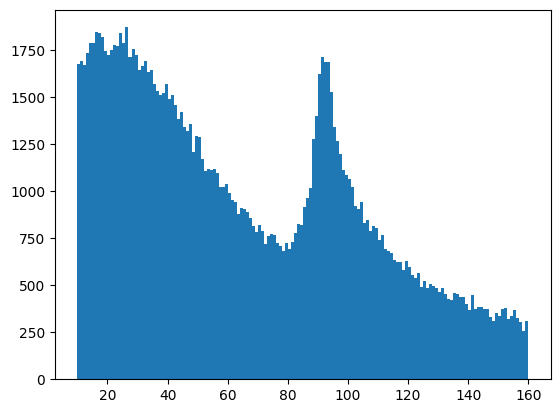

In [ ]:
plt.hist(cut_masses, bins=150, range=(10,160))
# additional info
plt.show()

In [ ]:
x_min, x_max = 10,160
bin_width = 1

Now, we will create the bins. We will do this with two arrays, one to define the edges of the bins and one to record all of the values at the centers of the bins. The first array can be created using np.arange(), which requires a start value, an end value (which is not included in the array), and a step size. These are the three parameters that we defined previously. When we create a scatter plot, we want to put a point in the center of each bin; thus, we need an array to contain all of these values. To create it, simply shift the bin starting values (all of the edges except for the last one) to the right by half of a bin's width.

In [ ]:
bin_edges = np.arange(start = x_min, stop = x_max+1, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2

Next, group the data into the bins that we defined using the function np.histogram(). This function takes two arguments: an array of data, and a definition of the bins. Two values are returned so you must declare two variables to hold the values. However, the second value simply returns the bin edges, which has already been defined, so it is not needed. It is common in Python to name a variable that we will not use and don't care about

In [ ]:
counts, _ = np.histogram(cut_masses, bins=bin_edges)

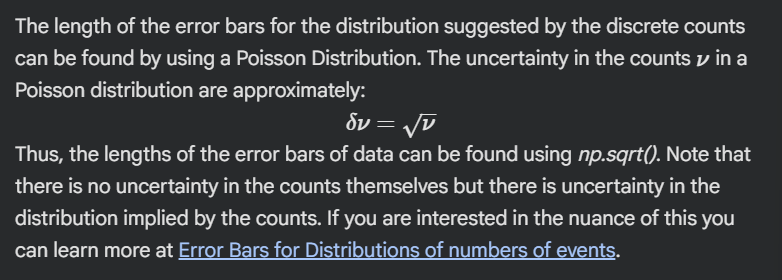

In [ ]:
count_errors = np.sqrt(counts)

Finally, an error bar plot can be created using np.errorbars(). The x-axis values will be the centers of the bins, the y-axis values will be the counts in each bin, and the y-axis errors will be the errors we found using the Poisson distribution. Setting fmt to 'ko' will simply determine the format of the plot. The plot is colored black by 'k' and set to circles with points by 'o'. The plot can be displayed by calling plt.show().

All of the previous steps should be grouped into one cell. Additional info has been added between plt.errorbars() and plt.show() to display a Z-peak with all of the appropriate labels on the axes and plot. Notice that in this case, the error bars are so small that they can't be seen under the markers.

<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2140/1686735108.py:12: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Di-lepton invarient mass [${m_{\mu\mu} \ or \ m_{ee}}$]', x=1, horizontalalignment = 'right')


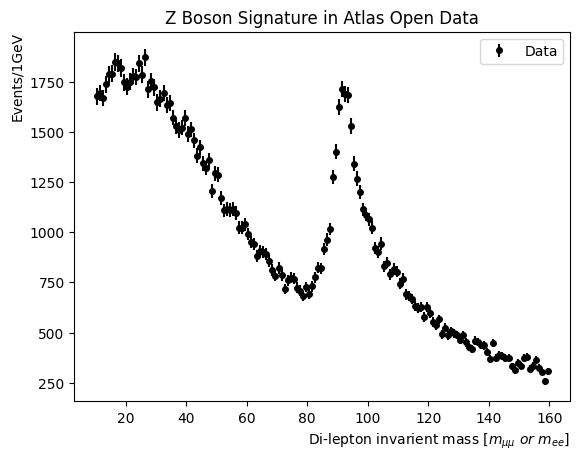

In [ ]:
# initial parameters
x_min, x_max = 10, 160
bin_width = 1
bin_edges = np.arange(start = x_min, stop = x_max+1, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2
counts, _ = np.histogram(cut_masses, bins=bin_edges)
count_errors = np.sqrt(counts)

#plot
plt.errorbar(x = bin_centers, y = counts, yerr = count_errors, fmt = 'ko', label = 'Data', markersize = 4)
plt.title('Z Boson Signature in Atlas Open Data')
plt.xlabel('Di-lepton invarient mass [${m_{\mu\mu} \ or \ m_{ee}}$]', x=1, horizontalalignment = 'right')
plt.ylabel('Events/' + str(bin_width) + 'GeV', y=1, horizontalalignment = 'right')
plt.legend()
plt.show()

# **Activties 2: Higgs Peak from a Monte Carlo Simulation**

In this activity, we will:

1. Turn the file into Arrays that can be used in Python.
2. Structure our data in a way to represent all possible Z boson combinations.
3. Create cuts to remove all invalid Z bosons.
4. Use the properties of 4-vectors to calculate the masses of the possible Z bosons.
5. Plot the masses of the possible Z bosons.
6. Use the Z boson masses and cuts to create more cuts to remove all invalid Higgs bosons.
7. Calculate the masses of the possible Higgs bosons.
8. [link text](https://)Plot the masses of the Higgs bosons. A Monte Carlo Simulation is a model of particle collisions that are measured by a detector

# Obtaining the Data

Now that we are searching for Higgs bosons, we have no need events with less than 4 leptons, so we can change the skim to '4lep'. Rather than working with 'data', we want to work with a simulation. For this reason, replace 'data' with '345060' as an argument in atom.get_urls(). This is the dataset ID for the decay of a Higgs boson into 4 leptons

In [ ]:
skim = '4lep'
# 345060 is the dataset id for ggh H ->ZZ ->LLLL
files_list = atom.get_urls('345060', skim, protocol = 'https', cache = True)

files_list only contains one file. It can be opened and turned into a structured array like was done in the Z boson activity.

In [ ]:
analysis = uproot.open(files_list[0]+':analysis')
attributes = ['pt', 'eta','phi', 'e', 'charge', 'flavor', 'tight']
aliases_dict = {'pt':'lep_pt','eta':'lep_eta','phi':'lep_phi','e':'lep_e',
                           'charge':'lep_charge','flavor':'lep_type','tight':'lep_isTightID'}
leps = analysis.arrays(attributes, aliases = aliases_dict)

Now we want to sort the leptons in descending order by transverse momentum. This can be done in the exact same way it was done in the Z boson activity (keeping the 4 highest pt leptons as opposed to 2).

In [ ]:
# sort leptons by transverse momentum, reduce no. of leptons per event to 4
leps = leps[np.argsort(leps.pt, axis=1)[:,::-1]][:,:4]

# **Convert Data Into 3D Array**

We want to eventually combine the data from the different combinations of the four leading leptons in each event in order to form a vector representing every possible Z boson that could have existed during each event. In the Z boson activity you could get away with combining attributes one by one, but in this activity, you want to simplify the code as much as you can. To do this, construct a 3D array to hold the data. This can be done by putting each piece of leps into an Ndarray declaration. First use the pseudorapidity to cartesian conversions to create 2D arrays for  px ,  py , and  pz  so that the first four components of vecs represent 4-momenta.

In [ ]:
# convert pt into px, py, pz
px = leps.pt*np.cos(leps.phi)
py = leps.pt*np.sin(leps.phi)
pz = leps.pt*np.sinh(leps.eta)

# Create an 3D array of lepton attributes that can easily sliced and
# added to form all possible Z Boson combinations
vecs = np.array([leps.e,px,py,pz,leps.charge,leps.flavor,leps.tight])

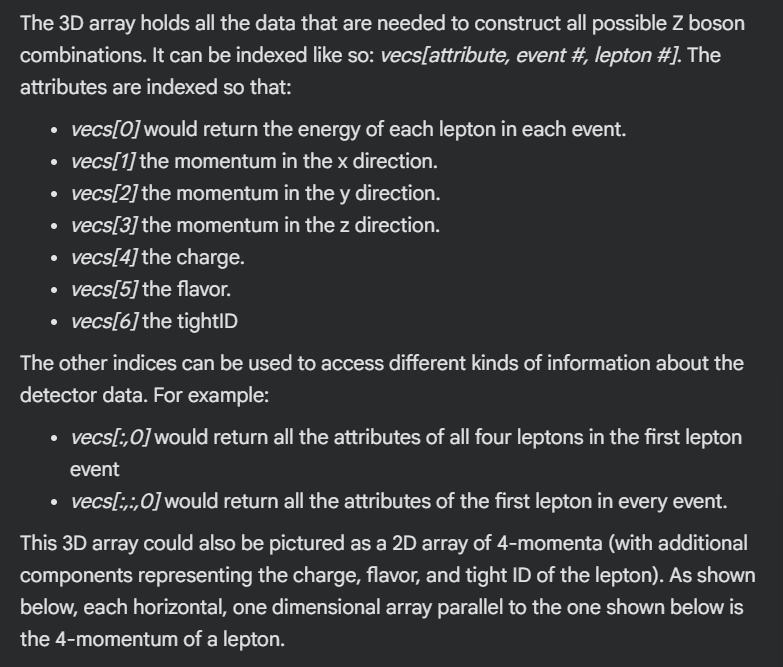

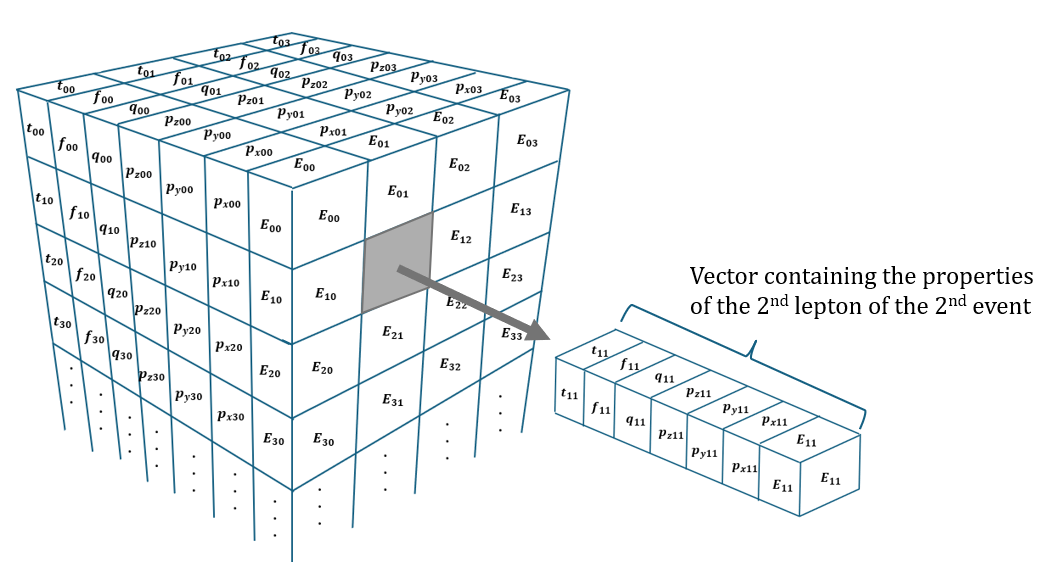

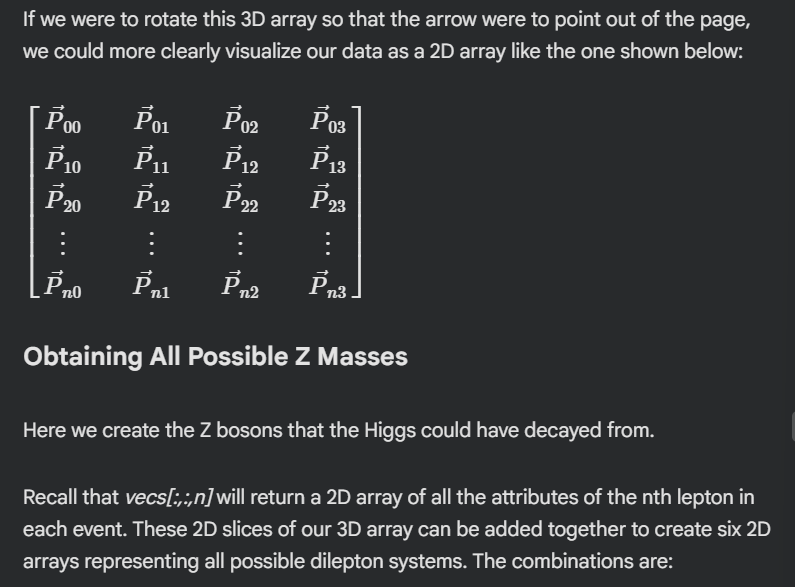

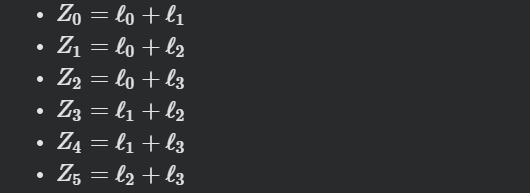

In [ ]:
Z0 = vecs[:,:,0] + vecs[:,:,1]
Z1 = vecs[:,:,0] + vecs[:,:,2]
Z2 = vecs[:,:,0] + vecs[:,:,3]
Z3 = vecs[:,:,1] + vecs[:,:,2]
Z4 = vecs[:,:,1] + vecs[:,:,3]
Z5 = vecs[:,:,2] + vecs[:,:,3]

These arrays should be combined into a 3D array of Z bosons using np.array().




In [ ]:
Zs = np.array([Z0,Z1,Z2,Z5,Z4,Z3])

The order in which the Z bosons are "stacked" in the the 3D array Zs does matter. The reason is so equivalent Z bosons will be in the same indices when we create our array of Higgs bosons.

Now we create the selections of the array of possible Z bosons to remove any di-lepton systems that don't exhibit Z-like behavior. To create cuts based on the values for the charge, flavor, and tight ID of the Z bosons, it must be taken into account that the vectors in the array are the vectors of a di-lepton system, rather than that of a single lepton. If the leptons are of opposite charge, then the vector for the di-lepton system will equal 0. If the flavor code for an electron is 11 and 13 for a muon, then flavor codes of 22 and 26 would signal Z-like behavior. The tight ID is an array of boolean conditions, and when arrays of boolean conditions are added together, they are first automatically converted to integers where True equals 1 and False equals 0. This means that in the tight ID conditions for the array Zs, 2 will mean both leptons satisfy tight ID.

In [ ]:
Z_charge_cut = Zs[:,4] == 0
Z_flavor_cut = (Zs[:,5] == 22) | (Zs[:,5] == 26)
Z_tight_cut = Zs[:,6] == 2

Z_mass is a 2D array of the masses of all possible Z bosons. It will be used to determine on and off shell Z Bosons.

In [49]:
Z_mass = np.sqrt(np.abs(Zs[:,0,:]**2-Zs[:,1,:]**2-Zs[:,2,:]**2-Zs[:,3,:]**2))

# Plotting All Possible Z masses
This step is unnecessary for creating a Higgs peak, but it will illuminate something crucial towards doing so.

Start by creating a cell to apply the cuts to Z_mass. Since it is a 2D array, you can not simply get rid of all of the non Z bosons by typing Zs[cuts]. Instead, you will insert a 0 at all locations where there is an invalid Z boson and later remove them once you have converted the array of masses into a 1D array. Inserting zeros can be done like so:

In [50]:
cut = Z_charge_cut & Z_flavor_cut & Z_tight_cut
cut_Z_mass = np.copy(Z_mass)
cut_Z_mass[cut] = 0

The selections you defined record True at all indices where Z-like behavior is seen. The notation in the cell defines all indices recorded True as 0. For these reasons, the ~ operator is inserted in the square brackets to flip every boolean condition so that True now stands for di-lepton systems that do not exhibit Z-like behavior.

Now, convert the array of masses into a 1D array with np.ndarray.flatten() which concatenates all the rows of Z_mass into a single array. Afterwards, remove all masses equal to zero from the 1D array.




In [51]:
Z_masses = np.ndarray.flatten(cut_Z_mass)
Z_masses = Z_masses[Z_masses != 0]

Next to plot error bar plot using matplotlib

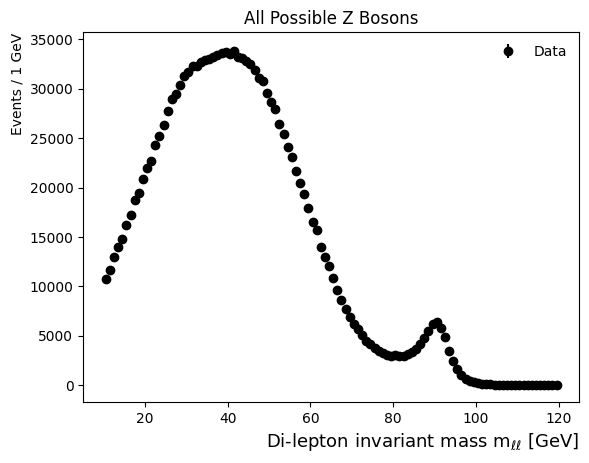

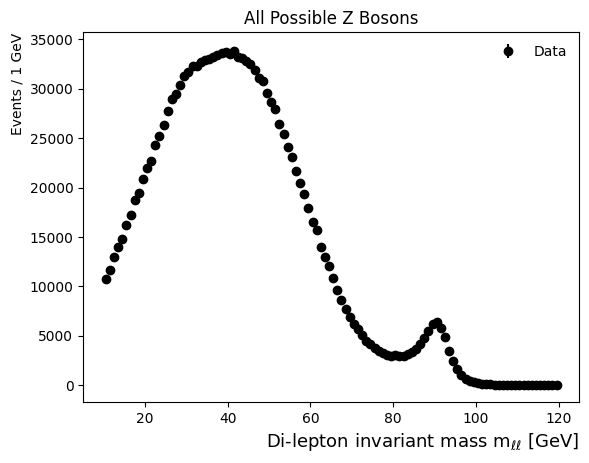

In [52]:
# x-axis range of the plot
xmin = 10 #GeV
xmax = 120 #GeV

# Histogram bin setup
bin_width = 1 #GeV
bin_edges = np.arange(start = xmin, stop = xmax + bin_width, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2

# Creating histogram from data
counts, _ = np.histogram(Z_masses, bins = bin_edges)
count_errors = np.sqrt(counts) # poisson approximation of the error

# Plot# x-axis range of the plot
xmin = 10 #GeV
xmax = 120 #GeV

# Histogram bin setup
bin_width = 1 #GeV
bin_edges = np.arange(start = xmin, stop = xmax + bin_width, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2

# Creating histogram from data
counts, _ = np.histogram(Z_masses, bins = bin_edges)
count_errors = np.sqrt(counts) # poisson approximation of the error

# Plot
axs = plt.gca()
axs.errorbar(x = bin_centers, y = counts, yerr = count_errors,
                    fmt = 'ko', # 'k' means black and 'o' is for circles
                    label = 'Data')
axs.set_xlabel(r'Di-lepton invariant mass $\mathrm{m_{\ell\ell}}$ [GeV]',
                     fontsize = 13, x = 1, horizontalalignment = 'right' )
axs.set_ylabel('Events / ' + str(bin_width) + ' GeV', y = 1, horizontalalignment = 'right')
plt.title('All Possible Z Bosons')
axs.legend(frameon = False)
plt.show()
axs = plt.gca()
axs.errorbar(x = bin_centers, y = counts, yerr = count_errors,
                    fmt = 'ko', # 'k' means black and 'o' is for circles
                    label = 'Data')
axs.set_xlabel(r'Di-lepton invariant mass $\mathrm{m_{\ell\ell}}$ [GeV]',
                     fontsize = 13, x = 1, horizontalalignment = 'right' )
axs.set_ylabel('Events / ' + str(bin_width) + ' GeV', y = 1, horizontalalignment = 'right')
plt.title('All Possible Z Bosons')
axs.legend(frameon = False)
plt.show()

Notice two distinct peaks: one at 91 GeV as we would expect for Z bosons, and a second peak around 34 GeV. This lower peak is the off-shell Z boson peak. It is important that we see both of these peaks present because they suggest the existence of a Higgs boson decay.

Something important to note is that this data does not represent the real Z bosons that existed, but rather every possible combinations of leptons that could have resulted in a Z boson. In reality, there can only be at most two Z bosons in a given event (since we narrowed down to four lepton events). More selections will narrow down our list of masses further so that we only show real possibilities for Higgs bosons.

# Obtaining Higgs Masses

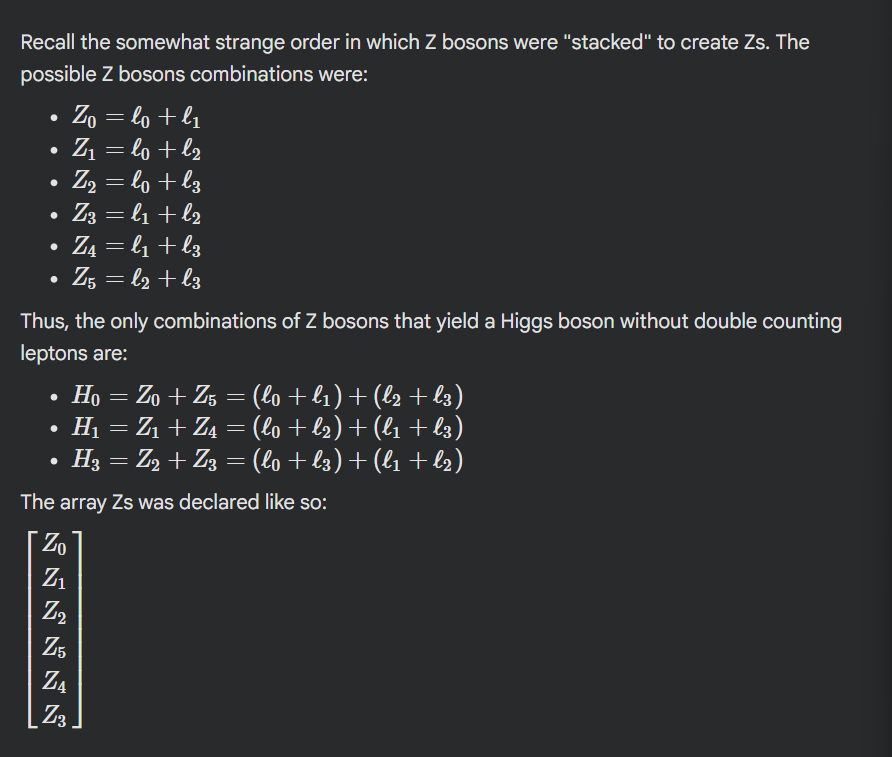

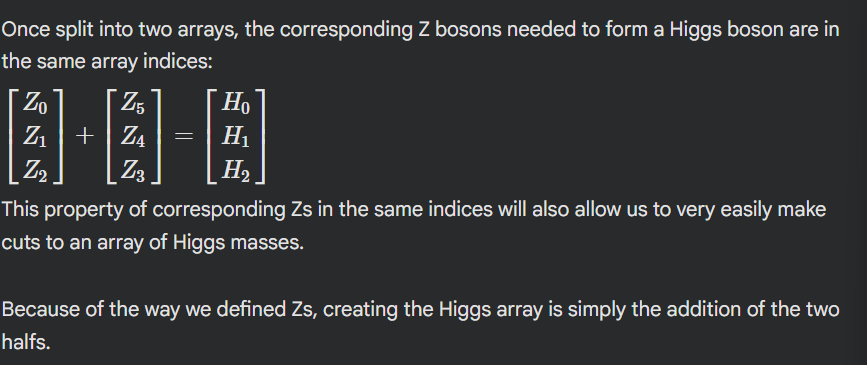

In [53]:
Higgs = Zs[:3] + Zs[3:]

Next, use Z_mass to create a cut to ensure that there is one on-shell and one off-shell Z boson per Higgs boson. The boundaries for these cuts are based on the Higgs boson discovery paper from 2012. There, they select for an on-shell Z boson with a mass between 50 GeV and 106 GeV and an off-shell Z boson that is between 17.5 GeV and 115GeV.

In [54]:
# split the array into two halfs
Z_mass_upper = Z_mass[:3]
Z_mass_lower = Z_mass[3:]

# define our mass constraints
Z_on_min, Z_on_max = 50, 106
Z_off_min, Z_off_max = 17.5, 115

# return true for all indices where a on\off shell pair exists
Z_up_is_on = (Z_mass_upper > Z_on_min) & (Z_mass_upper < Z_on_max)
Z_up_is_off = (Z_mass_upper > Z_off_min) & (Z_mass_upper < Z_off_max)
Z_low_is_on = (Z_mass_lower > Z_on_min) & (Z_mass_lower < Z_on_max)
Z_low_is_off = (Z_mass_lower > Z_off_min) & (Z_mass_lower < Z_off_max)

shell_cut = (Z_up_is_on & Z_low_is_off) | (Z_up_is_off & Z_low_is_on)

Below are cuts that ensure that the Z bosons which the Higgs boson decayed into both meet the charge, flavor, and tight ID conditions.

In [55]:
H_charge_cut = Z_charge_cut[:3] + Z_charge_cut[3:]
H_flavor_cut = Z_flavor_cut[:3] + Z_flavor_cut[3:]
H_tight_cut = Z_tight_cut[:3] + Z_tight_cut[3:]

H_mass is a 1D array of Higgs masses. While there are 3 possible combinations of leptons that yield a Higgs for every event, they all yield Higgs bosons of the same mass, so we only need to keep one row of masses. The only reason we are picky about the way the leptons are added was to make shell_cut to ensure that the Higgs were made of one on-shell Z and one off-shell Z.

In [56]:
H_mass = np.sqrt(np.abs(Higgs[:,0]**2-Higgs[:,1]**2-Higgs[:,2]**2-Higgs[:,3]**2))[0]

# Plotting Higgs Masses

Below is the application of the Higgs cuts to the Higgs array. Try different combinations of the cuts to see how the plot changes. The final array of Higgs masses will be one dimensional, since there can only be one Higgs created per event. To convert our 2D selections to a 1D selection, we will use the | operator to combine the different rows. For there to exist a valid Higgs boson in an event, only one of the rows needs to record True, so we use the | operator.

In [57]:
# choose cuts
cut = shell_cut & H_charge_cut & H_flavor_cut & H_tight_cut
# apply cuts
cut = cut[0] | cut[1] | cut[2]
cut_H_mass = H_mass[cut]

The Higgs masses can be graphed using the same procedure as the Z masses. The only change is that the lower bound should be 110 GeV and the upper bound 160 GeV to capture the domain we expect to see the Higgs peak.

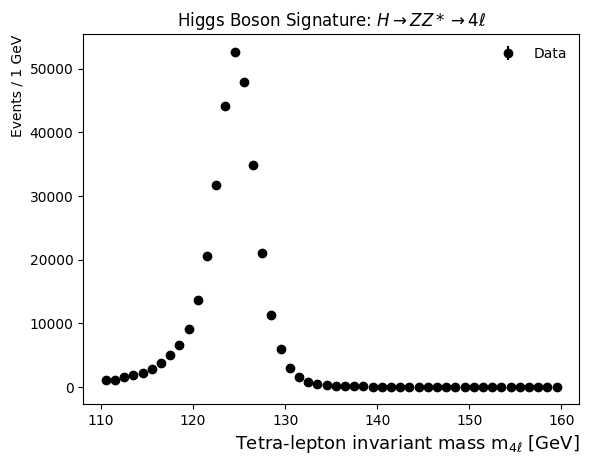

In [58]:
# x-axis range of the plot
xmin = 110 #GeV
xmax = 160 #GeV

# Histogram bin setup
bin_width = 1 #GeV
bin_edges = np.arange(start = xmin, stop = xmax + bin_width, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2

# Creating histogram from data
counts, _ = np.histogram(cut_H_mass, bins = bin_edges)
count_errors = np.sqrt(counts) # poisson approximation of the error

# Plot
axs = plt.gca()
axs.errorbar(x = bin_centers, y = counts, yerr = count_errors,
                    fmt = 'ko', # 'k' means black and 'o' is for circles
                    label = 'Data')
axs.set_xlabel(r'Tetra-lepton invariant mass $\mathrm{m_{4\ell}}$ [GeV]',
                     fontsize = 13, x = 1, horizontalalignment = 'right' )
axs.set_ylabel('Events / ' + str(bin_width) + ' GeV', y = 1, horizontalalignment = 'right')
plt.title('Higgs Boson Signature: ' + r'$H \rightarrow ZZ* \rightarrow 4\ell$')
axs.legend(frameon = False)
plt.show()

# Higgs Peak with Real Data

In [59]:
# this skim returns only events with 4 or more leptons per event
skim = "4lep"
files_list = atom.get_urls('data', skim, protocol='https', cache=True)

Unlike Activity 2, files_list contains more than one file. Where you can get away with only one file to get a distinct Z peak, the same is not true for a Higgs peak, because the Higgs boson is so rare. You must open all 16 files, convert them into structured arrays, then concatenate them together using np.concatenate(). This can be accomplished by first defining an empty list leps, then entering a for-loop where each file is turned into a structured array and concatenated to leps like what is shown below. This cell will take a few minutes to run on most systems; a formatted string within the loop will assure the user that the cell is running properly.

In [60]:
# empty array to be appended to in the for loop
leps = []

for file in files_list:
    print(f'Analyzing file: {file} ({files_list.index(file)+1}/{len(files_list)})')

    # open files and turn into a structured array
    analysis = uproot.open(file +':analysis')
    attributes = ['pt','eta','phi','e','charge','flavor','tight']
    aliases_dict = {'pt':'lep_pt','eta':'lep_eta','phi':'lep_phi','e':'lep_e',
                           'charge':'lep_charge','flavor':'lep_type','tight':'lep_isTightID'}
    leps_partial = analysis.arrays(attributes, aliases = aliases_dict)

    # append the current structured array to all previous structured arrays
    leps = np.concatenate([leps,leps_partial], axis=0)
print('Completed processing all files')

Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodD.4lep.root (1/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodE.4lep.root (2/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodF.4lep.root (3/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodG.4lep.root (4/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodH.4lep.root (5/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodJ.4lep.root (6/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data16_periodA.4lep.root (7/16)
Analyzing fil

# Analysis

The process of creating an array of Higgs masses from the set of real data is the same as with the Monte Carlo data

In [61]:
# sort leptons by transverse momentum, reduce number of leptons per event to 4
leps = leps[np.argsort(leps.pt, axis=1)[:,::-1]][:,:4]

# convert pt into px, py, pz
px = leps.pt*np.cos(leps.phi)
py = leps.pt*np.sin(leps.phi)
pz = leps.pt*np.sinh(leps.eta)

# Create an 3D Array of lepton attributes that can be easily sliced and
# added to form all possible Z Boson combinations
vecs = np.array([leps.e,px,py,pz,leps.charge,leps.flavor,leps.tight])

Z0 = vecs[:,:,0] + vecs[:,:,1]
Z1 = vecs[:,:,0] + vecs[:,:,2]
Z2 = vecs[:,:,0] + vecs[:,:,3]
Z3 = vecs[:,:,1] + vecs[:,:,2]
Z4 = vecs[:,:,1] + vecs[:,:,3]
Z5 = vecs[:,:,2] + vecs[:,:,3]
Zs = np.array([Z0,Z1,Z2,Z5,Z4,Z3])

Z_charge_cut = Zs[:,4] == 0
Z_flavor_cut = (Zs[:,5] == 22) | (Zs[:,5] == 26)
Z_tight_cut = Zs[:,6] == 2

Z_mass = np.sqrt(np.abs(Zs[:,0,:]**2-Zs[:,1,:]**2-Zs[:,2,:]**2-Zs[:,3,:]**2))

Try different combination of cuts and see how the plot changes

In [62]:
cut = Z_charge_cut & Z_flavor_cut & Z_tight_cut
cut_Z_mass = np.copy(Z_mass)
cut_Z_mass[~cut] = 0

Z_masses = np.ndarray.flatten(cut_Z_mass)
Z_masses = Z_masses[Z_masses != 0]

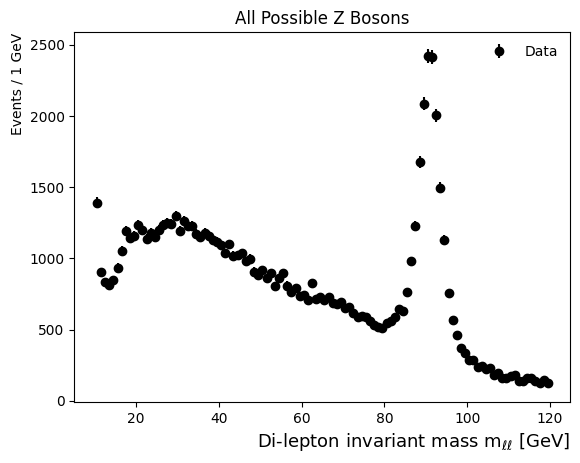

In [63]:
# x-axis range of the plot
xmin = 10 #GeV
xmax = 120 #GeV

# Histogram bin setup
bin_width = 1 #GeV
bin_edges = np.arange(start = xmin, stop = xmax + bin_width, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2

# Creating histogram from data
counts, _ = np.histogram(Z_masses, bins = bin_edges)
count_errors = np.sqrt(counts) # poisson approximation of the error

# Plot
axs = plt.gca()
axs.errorbar(x = bin_centers, y = counts, yerr = count_errors,
                    fmt = 'ko', # 'k' means black and 'o' is for circles
                    label = 'Data')
axs.set_xlabel(r'Di-lepton invariant mass $\mathrm{m_{\ell\ell}}$ [GeV]',
                     fontsize = 13, x = 1, horizontalalignment = 'right' )
axs.set_ylabel('Events / ' + str(bin_width) + ' GeV', y = 1, horizontalalignment = 'right')
plt.title('All Possible Z Bosons')
axs.legend(frameon = False)
plt.show()

In [64]:
Higgs = Zs[:3] + Zs[3:]

# split the array into two halfs
Z_mass_upper = Z_mass[:3]
Z_mass_lower = Z_mass[3:]

# define our mass constraints
Z_on_min, Z_on_max = 50, 106
Z_off_min, Z_off_max = 17.5, 115

# return true for all indices where a on\off shell pair exists
Z_up_is_on = (Z_mass_upper > Z_on_min) & (Z_mass_upper < Z_on_max)
Z_up_is_off = (Z_mass_upper > Z_off_min) & (Z_mass_upper < Z_off_max)
Z_low_is_on = (Z_mass_lower > Z_on_min) & (Z_mass_lower < Z_on_max)
Z_low_is_off = (Z_mass_lower > Z_off_min) & (Z_mass_lower < Z_off_max)

shell_cut = (Z_up_is_on & Z_low_is_off) | (Z_up_is_off & Z_low_is_on)

H_charge_cut = Z_charge_cut[:3] & Z_charge_cut[3:]
H_flavor_cut = Z_flavor_cut[:3] & Z_flavor_cut[3:]
H_tight_cut = Z_tight_cut[:3] & Z_tight_cut[3:]

H_mass = np.sqrt(np.abs(Higgs[:,0]**2-Higgs[:,1]**2-Higgs[:,2]**2-Higgs[:,3]**2))[0]

In [65]:
# choose cuts
cut = shell_cut & H_charge_cut & H_flavor_cut & H_tight_cut
# apply cuts
cut = cut[0] | cut[1] | cut[2]
H_mass = H_mass[cut]

When all of the cuts are applied, the counts per 1 GeV bin will be low compared to the Monte Carlo data. To see a distinct peak at the mass of the Higgs boson, the bin width has been increased.

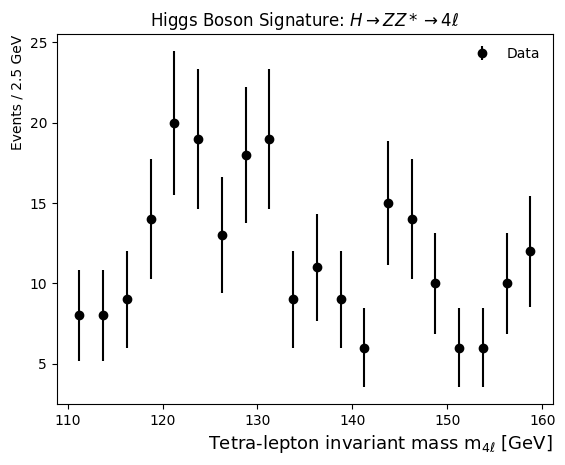

In [66]:
# x-axis range of the plot
xmin = 110 #GeV
xmax = 160 #GeV

# Histogram bin setup
bin_width = 2.5 #GeV
bin_edges = np.arange(start = xmin, stop = xmax + bin_width, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2

# Creating histogram from data
counts, _ = np.histogram(H_mass, bins = bin_edges)
count_errors = np.sqrt(counts) # poisson approximation of the error

# Plot
axs = plt.gca()
axs.errorbar(x = bin_centers, y = counts, yerr = count_errors,
                    fmt = 'ko', # 'k' means black and 'o' is for circles
                    label = 'Data')
axs.set_xlabel(r'Tetra-lepton invariant mass $\mathrm{m_{4\ell}}$ [GeV]',
                     fontsize = 13, x = 1, horizontalalignment = 'right' )
axs.set_ylabel('Events / ' + str(bin_width) + ' GeV', y = 1, horizontalalignment = 'right')
plt.title('Higgs Boson Signature: ' + r'$H \rightarrow ZZ* \rightarrow 4\ell$')
axs.legend(frameon = False)
plt.show()